# Student Digital Life: Screen Time & Academic Performance

Exploratory analysis of a synthetic dataset (15,000 students) looking at how study time, smartphone/social media/gaming/streaming usage, sleep, and other habits relate to final exam scores.

An interactive Plotly Dash dashboard built on the same data lives in [`dashboard.py`](dashboard.py) — run it separately with `python dashboard.py`.

**Data:** `student_digital_life.csv` — [Digital Distraction vs Academic Performance](https://www.kaggle.com/datasets/neurocipher/digital-distraction-vs-academic-performance) on Kaggle (18 columns, 15,000 rows, no missing values or duplicates).

In [1]:
import pandas as pd
df = pd.read_csv("student_digital_life.csv")
df

,student_id,age,gender,study_hours_per_day,smartphone_usage_hours,social_media_hours,gaming_hours,streaming_hours,sleep_hours,exercise_hours,class_attendance_percent,assignment_completion_percent,caffeine_intake_cups,mental_health_status,parent_education_level,internet_quality,motivation_level,final_exam_score
0,1,21,Female,3.01,0.26,1.77,0.26,1.71,5.32,0.70,64.87,74.11,2,Good,Masters,Average,6.32,82.70
1,2,23,Female,5.84,8.02,3.30,0.96,0.00,5.99,1.99,85.38,80.68,3,Average,Masters,Poor,2.52,85.65
2,3,20,Female,7.80,10.13,0.00,2.23,2.54,6.36,1.82,76.15,79.69,2,Good,HighSchool,Poor,3.98,88.14
3,4,20,Female,0.00,1.15,1.32,4.19,0.27,7.86,0.18,84.41,79.07,0,Average,HighSchool,Average,4.77,54.81
4,5,24,Male,7.23,1.39,2.21,4.67,2.75,7.88,0.28,81.13,65.40,4,Good,HighSchool,Average,8.77,84.34
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,14996,22,Female,4.40,5.47,0.00,2.10,1.45,8.26,0.05,88.61,73.31,1,Poor,Masters,Average,6.06,66.39
14996,14997,24,Male,6.21,11.89,3.98,3.92,3.83,7.07,0.00,80.00,73.04,0,Poor,Bachelors,Average,10.00,73.38
14997,14998,21,Male,6.61,5.82,2.33,1.33,2.01,3.91,1.67,80.68,90.72,1,Poor,Bachelors,Average,10.00,98.00
14998,14999,22,Female,3.67,4.58,2.51,4.54,3.80,8.35,1.67,81.76,48.75,1,Good,HighSchool,Average,6.22,68.07


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     15000 non-null  int64  
 1   age                            15000 non-null  int64  
 2   gender                         15000 non-null  str    
 3   study_hours_per_day            15000 non-null  float64
 4   smartphone_usage_hours         15000 non-null  float64
 5   social_media_hours             15000 non-null  float64
 6   gaming_hours                   15000 non-null  float64
 7   streaming_hours                15000 non-null  float64
 8   sleep_hours                    15000 non-null  float64
 9   exercise_hours                 15000 non-null  float64
 10  class_attendance_percent       15000 non-null  float64
 11  assignment_completion_percent  15000 non-null  float64
 12  caffeine_intake_cups           15000 non-null  int64  
 1

In [3]:
df.describe()

,student_id,age,study_hours_per_day,smartphone_usage_hours,social_media_hours,gaming_hours,streaming_hours,sleep_hours,exercise_hours,class_attendance_percent,assignment_completion_percent,caffeine_intake_cups,motivation_level,final_exam_score
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,7500.500000,21.024400,4.511505,5.503475,3.516837,2.241304,1.829245,6.997377,1.234827,84.631745,79.445435,1.504933,5.988216,80.344360
std,4330.271354,2.594299,1.981043,2.437488,1.767000,1.468125,1.132042,1.456868,0.827273,9.452752,13.918023,1.227060,1.949031,18.434455
min,1.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.500000,0.000000,44.960000,30.000000,0.000000,1.000000,2.630000
25%,3750.750000,19.000000,3.167500,3.830000,2.280000,1.110000,0.990000,5.970000,0.600000,78.180000,70.007500,1.000000,4.650000,68.730000
50%,7500.500000,21.000000,4.510000,5.480000,3.490000,2.175000,1.780000,6.990000,1.190000,84.895000,80.220000,1.000000,6.000000,83.745000
75%,11250.250000,23.000000,5.840000,7.150000,4.710000,3.260000,2.600000,8.030000,1.800000,91.650000,90.275000,2.000000,7.340000,97.810000
max,15000.000000,25.000000,11.780000,14.000000,9.000000,8.000000,6.000000,10.000000,4.660000,100.000000,100.000000,8.000000,10.000000,100.000000


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df["age"].value_counts()


age
17    1718
25    1714
20    1706
23    1701
22    1694
24    1673
19    1648
18    1577
21    1569
Name: count, dtype: int64

In [6]:
df["sleep_hours"].value_counts()

sleep_hours
10.00    355
3.50     133
6.95      61
6.35      55
7.28      53
        ... 
4.30       1
3.76       1
3.55       1
3.68       1
3.52       1
Name: count, Length: 649, dtype: int64

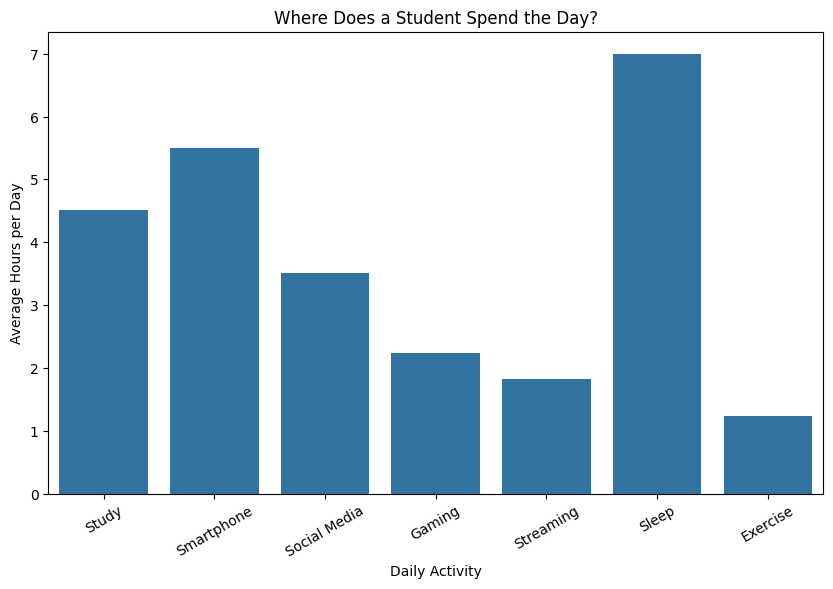

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

time_columns = [
    'study_hours_per_day',
    'smartphone_usage_hours',
    'social_media_hours',
    'gaming_hours',
    'streaming_hours',
    'sleep_hours',
    'exercise_hours'
]

time_labels = [
    'Study',
    'Smartphone',
    'Social Media',
    'Gaming',
    'Streaming',
    'Sleep',
    'Exercise'
]

time_means = df[time_columns].mean()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=time_labels,
    y=time_means.values
)

plt.title('Where Does a Student Spend the Day?')
plt.xlabel('Daily Activity')
plt.ylabel('Average Hours per Day')
plt.xticks(rotation=30)
plt.show()

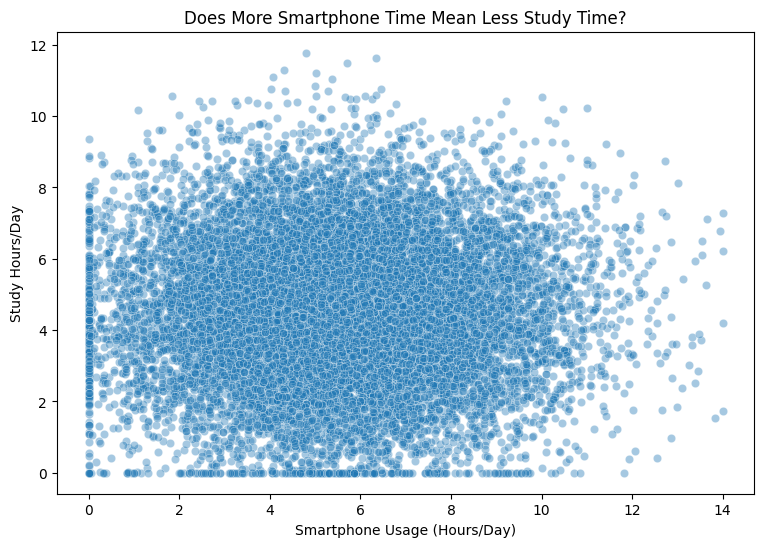

In [8]:


plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='smartphone_usage_hours',
    y='study_hours_per_day',
    alpha=0.4
)

plt.title('Does More Smartphone Time Mean Less Study Time?')
plt.xlabel('Smartphone Usage (Hours/Day)')
plt.ylabel('Study Hours/Day')

plt.show()

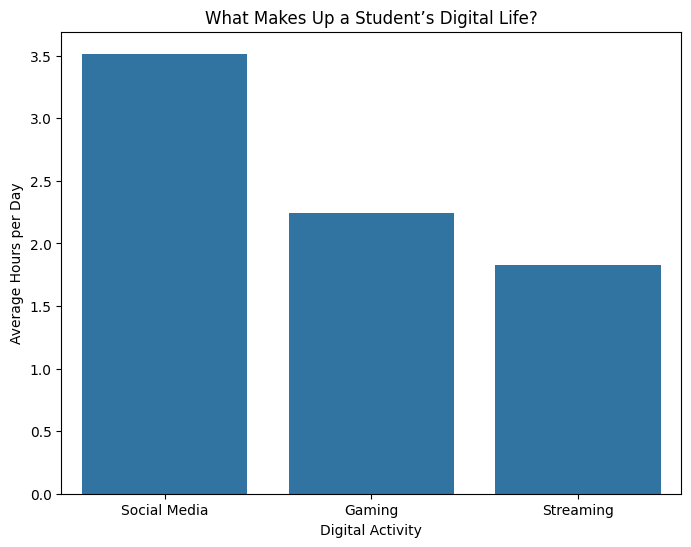

In [9]:

digital_columns = [
    'social_media_hours',
    'gaming_hours',
    'streaming_hours'
]

digital_labels = [
    'Social Media',
    'Gaming',
    'Streaming'
]

digital_means = df[digital_columns].mean()

plt.figure(figsize=(8, 6))

sns.barplot(
    x=digital_labels,
    y=digital_means.values
)

plt.title('What Makes Up a Student’s Digital Life?')
plt.xlabel('Digital Activity')
plt.ylabel('Average Hours per Day')

plt.show()

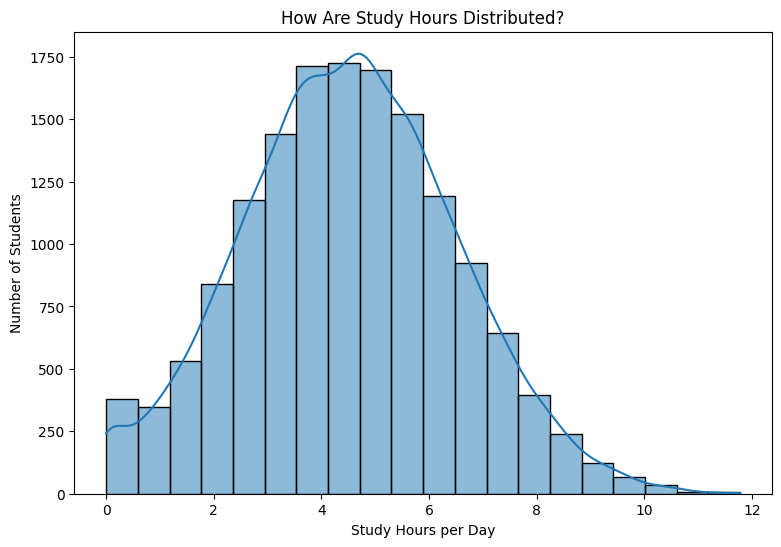

In [10]:

plt.figure(figsize=(9, 6))

sns.histplot(
    data=df,
    x='study_hours_per_day',
    bins=20,
    kde=True
)

plt.title('How Are Study Hours Distributed?')
plt.xlabel('Study Hours per Day')
plt.ylabel('Number of Students')

plt.show()

In [11]:


same_study = df[
    (df['study_hours_per_day'] >= 4) &
    (df['study_hours_per_day'] < 5)
].copy()

digital_columns = [
    'social_media_hours',
    'gaming_hours',
    'streaming_hours'
]

# Identify the dominant digital activity for each student
same_study['digital_fingerprint'] = (
    same_study[digital_columns]
    .idxmax(axis=1)
    .str.replace('_hours', '', regex=False)
    .str.replace('_', ' ')
    .str.title()
)

print("Students in comparison group:", len(same_study))
print("\nDigital Fingerprints:")
print(same_study['digital_fingerprint'].value_counts())

Students in comparison group: 2958

Digital Fingerprints:
digital_fingerprint
Social Media    1909
Gaming           690
Streaming        359
Name: count, dtype: int64


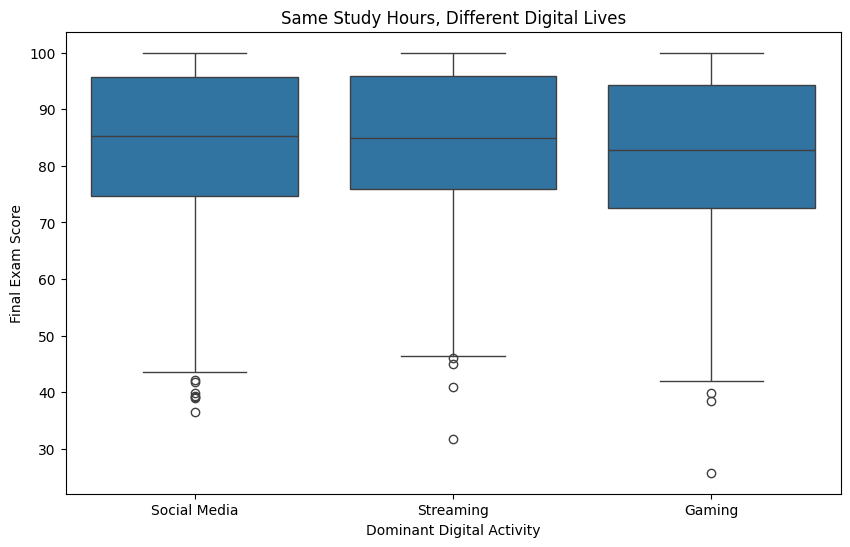

In [12]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=same_study,
    x='digital_fingerprint',
    y='final_exam_score'
)

plt.title('Same Study Hours, Different Digital Lives')
plt.xlabel('Dominant Digital Activity')
plt.ylabel('Final Exam Score')

plt.show()

In [13]:


score_summary = (
    same_study
    .groupby('digital_fingerprint')['final_exam_score']
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
    .round(2)
    .sort_values('mean', ascending=False)
)

print(score_summary)

                     count   mean  median    std    min    max
digital_fingerprint                                           
Streaming              359  84.14   84.85  13.25  31.62  100.0
Social Media          1909  83.62   85.19  13.52  36.51  100.0
Gaming                 690  81.82   82.82  14.18  25.74  100.0


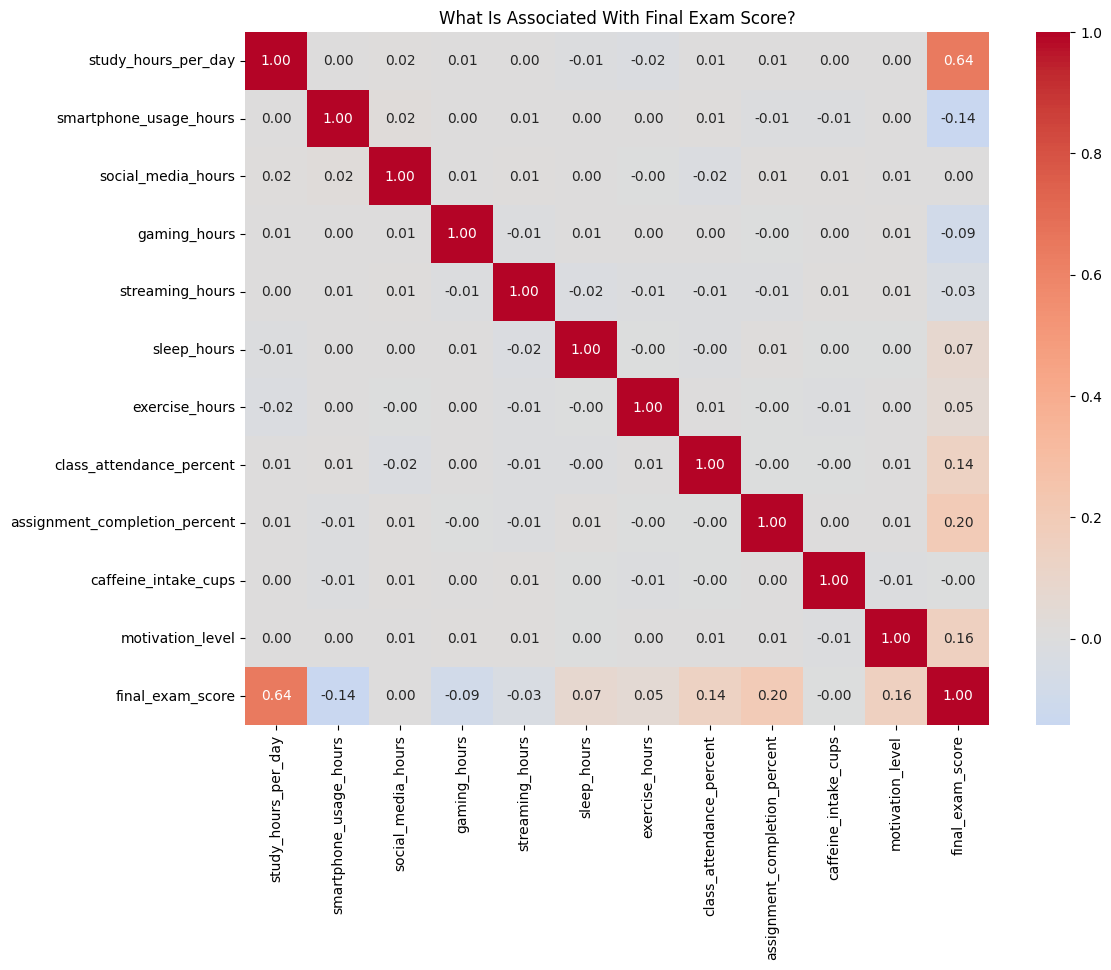

In [14]:


performance_columns = [
    'study_hours_per_day',
    'smartphone_usage_hours',
    'social_media_hours',
    'gaming_hours',
    'streaming_hours',
    'sleep_hours',
    'exercise_hours',
    'class_attendance_percent',
    'assignment_completion_percent',
    'caffeine_intake_cups',
    'motivation_level',
    'final_exam_score'
]

corr = df[performance_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('What Is Associated With Final Exam Score?')
plt.show()

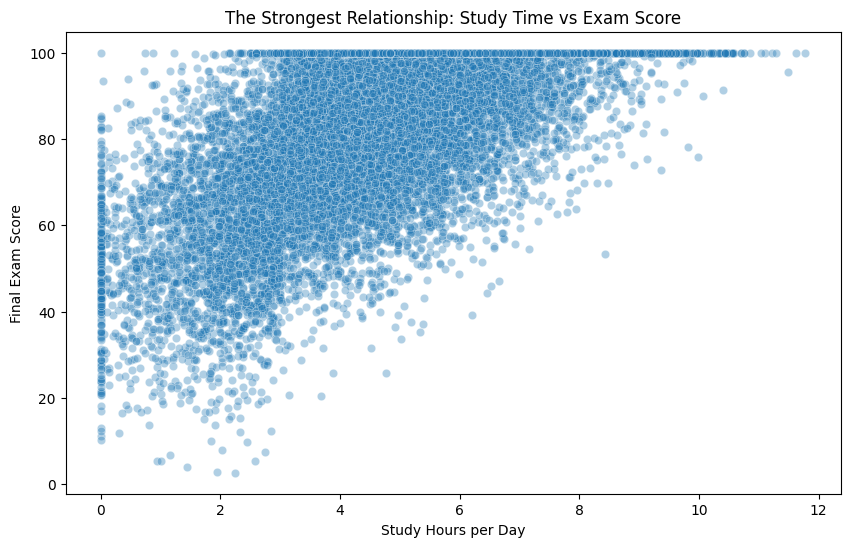

In [15]:


plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='study_hours_per_day',
    y='final_exam_score',
    alpha=0.35
)

plt.title('The Strongest Relationship: Study Time vs Exam Score')
plt.xlabel('Study Hours per Day')
plt.ylabel('Final Exam Score')

plt.show()

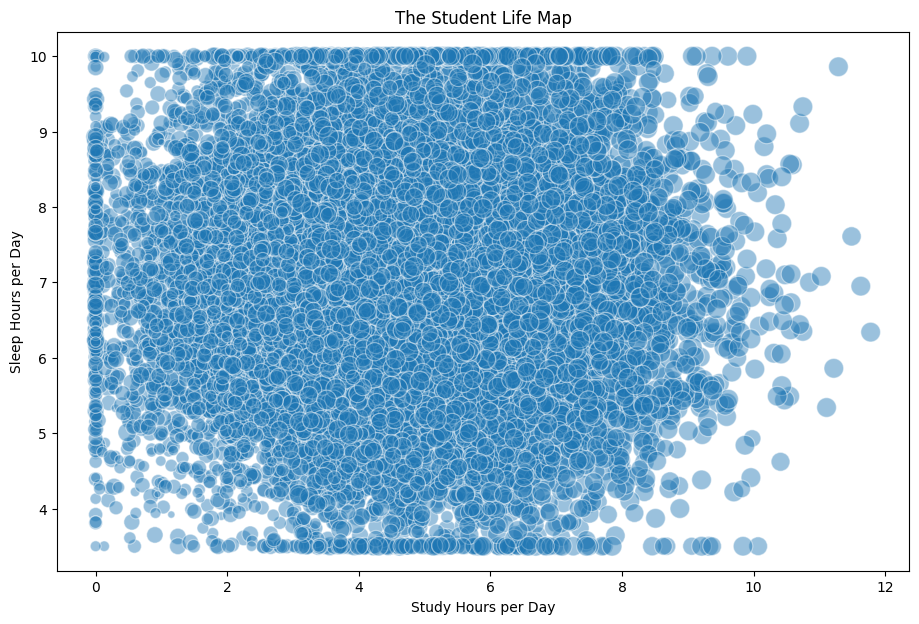

In [16]:


plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x='study_hours_per_day',
    y='sleep_hours',
    size='final_exam_score',
    sizes=(20, 200),
    alpha=0.45,
    legend=False
)

plt.title('The Student Life Map')
plt.xlabel('Study Hours per Day')
plt.ylabel('Sleep Hours per Day')

plt.show()

In [17]:


df['performance_profile'] = pd.cut(
    df['study_hours_per_day'],
    bins=[-1, 4, float('inf')],
    labels=['Lower Study Time', 'Higher Study Time']
)

df['score_profile'] = pd.cut(
    df['final_exam_score'],
    bins=[-1, 60, float('inf')],
    labels=['Lower Score', 'Higher Score']
)

df['student_profile'] = (
    df['performance_profile'].astype(str)
    + ' + '
    + df['score_profile'].astype(str)
)

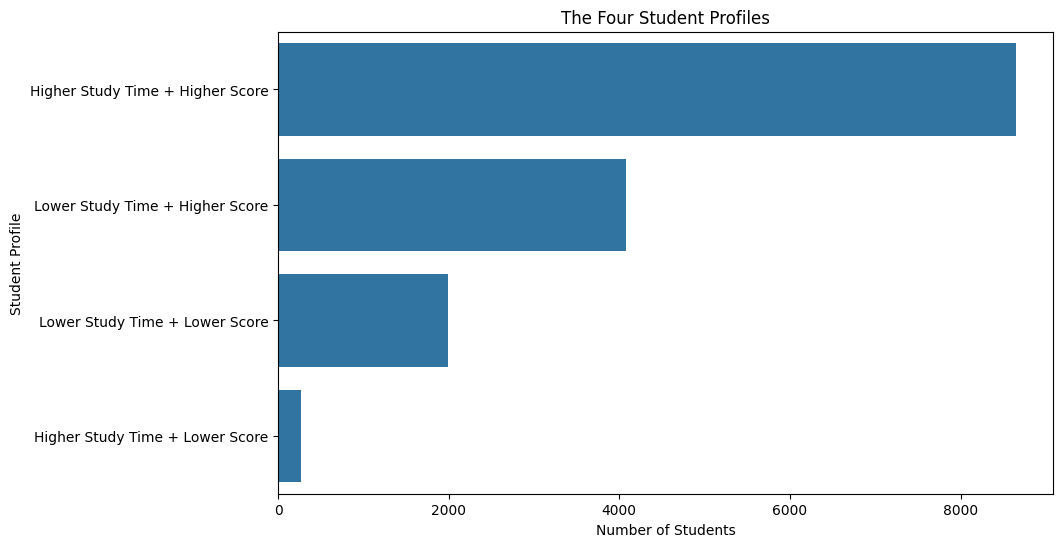

In [18]:
profile_counts = df['student_profile'].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=profile_counts.values,
    y=profile_counts.index
)

plt.title('The Four Student Profiles')
plt.xlabel('Number of Students')
plt.ylabel('Student Profile')

plt.show()

Average habits and outcomes for each of the four study-time × score profiles:

In [19]:
profile_features = [
    'study_hours_per_day',
    'smartphone_usage_hours',
    'sleep_hours',
    'exercise_hours',
    'class_attendance_percent',
    'assignment_completion_percent',
    'motivation_level',
    'final_exam_score'
]

profile_summary = df.groupby('student_profile')[profile_features].mean()

profile_summary

,study_hours_per_day,smartphone_usage_hours,sleep_hours,exercise_hours,class_attendance_percent,assignment_completion_percent,motivation_level,final_exam_score
student_profile,,,,,,,,
Higher Study Time + Higher Score,5.834123,5.496015,7.006825,1.230090,84.861794,79.667537,6.020905,89.798080
Higher Study Time + Lower Score,4.902491,6.073407,6.359744,1.169267,79.764249,69.955348,5.090696,53.146300
Lower Study Time + Higher Score,2.917884,5.145075,7.075934,1.270953,85.412461,81.429481,6.178984,78.594024
Lower Study Time + Lower Score,1.979739,6.192380,6.882706,1.190336,82.699408,75.714664,5.578223,46.598429
